# Anatomy of a converged two-hidden-layer network: how 62 rows and 60 units with a direct readout implement the depth-5 tree

Generalisation of `run56_network_anatomy.ipynb` to every **two-hidden-layer** run of the design series (runs 42-46 of the first notebook
and runs 55-61 of notebook 2). `RUN` in the first cell selects the run and `EPOCH` the snapshot (default: the last one stored); the
written findings are for the anchor run 56 at its last epoch, and every table and plot recomputes for the selected run. Runs that did not
converge to the designed solution (55, 57, 58, 59, 61) are handled: cells report which nodes lack a row and which units lack a cue veto
instead of assuming the complete structure.

The first layer is read as a bank of features `f_r(x) = ||w_r|| relu(+-a_n(x))` on the ODT normals (`a_n = u_n . x`, each row labelled
by its closest normal), every second-layer unit as a weighted sum of these features through a ReLU, and the logit as the plain weighted
sum of the units. Sections: 1 the first layer as a feature bank (and the shared ancestor tilt of each pole pair); 2 the second layer in the
feature basis (vetoes and backgrounds); 3 the level-3 units as leaf detectors; 4 the lower-level units; 5 the readout: contributions,
ablations, the decision near the boundary, and the sharp-veto limit.


In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, pickle
%load_ext autoreload
%autoreload 2
from layer_lenses.designed_init import NODE_LEVEL, node_ancestors, HIERARCHY_TARGETS
from layer_lenses.init_sweep import SweepRunSpec, build_data, load_tree
np.set_printoptions(linewidth=200, precision=2, suppress=True); pd.set_option("display.width", 220)
RUNS = {42: "hierarchy_equiv2L_62", 43: "hierarchy_equiv2L_62_outx41", 44: "hierarchy_equiv2L_62_outfrozen", 45: "hierarchy_equiv2L_62_sadam01", 46: "hierarchy_equiv2L_62_sadam03",   # first notebook: run 38 without the third layer (free training, 1M points)
        55: "hd2_run55_phased2_2L_10M", 56: "hd2_run56_phased2_2L_outx80_10M", 57: "hd2_run57_phase1_proj_u0", 58: "hd2_run58_phase1_proj_u1",                             # notebook 2 (phased, 10M points)
        59: "hd2_run59_sgd_lr02_2000", 60: "hd2_run60_sgd_lr1_1000", 61: "hd2_run61_phase1_randcue_n1"}
RUN = 56                                                                                                                                  # <- select the run
RESULTS = Path("../results/designed_init"); RUNDIR = RESULTS / RUNS[RUN]; tree = load_tree(RUNDIR / "tree.npz"); U = tree.w_list
z = np.load(RUNDIR / "replay/weights.npz"); EPOCHS = list(z["epochs"]); EPOCH = EPOCHS[-1]                                                     # <- select the snapshot
meta = pickle.load(open(RUNDIR / "replay/meta.pkl", "rb")); ups = np.array(meta["design"]["unit_path_sign"]); ubs = np.array(meta["design"]["unit_block_sign"]); unode = np.array(meta["design"]["unit_node"])
N_ROWS, N_UNITS = z["w__hidden_layers.0.weight"].shape[1], z["w__hidden_layers.1.weight"].shape[1]; assert "w__hidden_layers.2.weight" not in z.files, "this notebook is for two-hidden-layer runs"
x, y = build_data(SweepRunSpec(tree_seed=5178, data_seed=999_777, init_seed=0, batch_size=1, n_train=100_000), tree); y = y.astype(np.float64); A = x @ U.T      # a_n(x) for the 31 normals
def reach4(A):
    node = np.zeros(len(A), int)
    for lvl in range(4): node = 2 * node + 1 + (A[np.arange(len(A)), node] > 0)
    return node
m_reached = reach4(A); assert np.array_equal(np.sign(A[np.arange(len(A)), m_reached]), y); am = A[np.arange(len(A)), m_reached]
utype = np.array([f"({'+' if b > 0 else '-'}B,{'+' if s > 0 else '-'})" for b, s in zip(ubs, ups)])
def use_epoch(e):
    """Load the snapshot of epoch e into the notebook globals: weights, rows as (node, pole) features, forward pass, readout."""
    g = globals(); g["EPOCH"] = e; W1, W2, Wo = (z[k][EPOCHS.index(e)].astype(np.float64) for k in ["w__hidden_layers.0.weight", "w__hidden_layers.1.weight", "w__output_layer.weight"])
    nrm = np.linalg.norm(W1, axis=1); Cos = W1 / nrm[:, None] @ U.T; top = np.abs(Cos).argmax(1); pole = np.sign(Cos[np.arange(N_ROWS), top]).astype(int); cos = np.abs(Cos).max(1)
    g.update(W1=W1, W2=W2, Wo=Wo, nrm=nrm, Cos=Cos, top=top, pole=pole, cos=cos, rname=np.array([f"{'+' if pole[r] > 0 else '-'}u{top[r]}" for r in range(N_ROWS)]), Weff=W2 * nrm[None, :],
             F=np.maximum(pole[None, :] * A[:, top], 0), h1=np.maximum(x @ W1.T, 0))
    g["h2"] = np.maximum(g["h1"] @ W2.T, 0); g["readout"] = Wo.ravel(); g["logit"] = g["h2"] @ g["readout"]; g["contrib"] = g["h2"] * g["readout"][None, :]
    print(f"run {RUN} ({RUNS[RUN]}), epoch {e} of {EPOCHS[-1]}: test error {((g['logit'] >= 0) != (y > 0)).mean():.5f} on {len(y)} points; logit rms {np.sqrt((g['logit'] ** 2).mean()):.1f}; "
          f"readout sign = path sign on {(np.sign(g['readout']) == ups).mean():.2f} of units, |readout| mean {np.abs(g['readout']).mean():.1f}; rows at |cos| > 0.95 with a normal: {(cos > 0.95).sum()} / {N_ROWS}")
use_epoch(EPOCH)


run 56 (hd2_run56_phased2_2L_outx80_10M), epoch 1000 of 1000: test error 0.00366 on 100000 points; logit rms 15.3; readout sign = path sign on 1.00 of units, |readout| mean 53.8; rows at |cos| > 0.95 with a normal: 62 / 62


## 1. The first layer as a bank of one-sided features on the tree's normals


In [2]:
rows = pd.DataFrame({"row": range(N_ROWS), "kind": ["probe"] * 30 + ["cue"] * 32 + ["spare"] * (N_ROWS - 62), "node": top, "pole": pole, "level": NODE_LEVEL[top], "norm": nrm, "cos": cos, "off_span_frac": np.linalg.norm(W1 - (W1 @ U.T) @ U, axis=1) / nrm})
print(rows.groupby(["kind", "level"]).agg(n=("row", "size"), norm_mean=("norm", "mean"), norm_min=("norm", "min"), norm_max=("norm", "max"), cos_min=("cos", "min"), off_span_max=("off_span_frac", "max")).round(3))
pairs = sorted(zip(top[cos > 0.95], pole[cos > 0.95])); complete = sorted(set(pairs)) == sorted((n, p) for n in range(31) for p in (1, -1)) and len(pairs) == 62
print("every (node, pole) pair has exactly one aligned row:", complete)
if not complete:
    from collections import Counter
    cnt = Counter(pairs); print("  (node, pole) pairs with no aligned row:", [(n, p) for n in range(31) for p in (1, -1) if cnt[(n, p)] == 0], "| with several:", {k: v for k, v in cnt.items() if v > 1}, "| rows not aligned (|cos| <= 0.95):", [int(r) for r in np.where(cos <= 0.95)[0]])
print("feature approximation |h1 - norm * relu(pole a_node)| max over points / rows:", np.abs(h1 - F * nrm).max().round(3), "(relative to row norm x typical |a| ~", (nrm.mean() * 0.08).round(2), ")")


              n  norm_mean  norm_min  norm_max  cos_min  off_span_max
kind  level                                                          
cue   4      32      0.951     0.415     1.343    0.987         0.012
probe 0       2     17.819    17.767    17.872    1.000         0.001
      1       4     12.351    12.318    12.390    0.999         0.001
      2       8      9.380     9.303     9.467    0.999         0.002
      3      16      7.227     7.095     7.417    0.999         0.003
every (node, pole) pair has exactly one aligned row: True
feature approximation |h1 - norm * relu(pole a_node)| max over points / rows: 0.177 (relative to row norm x typical |a| ~ 0.4 )


In [3]:
# The residual of each row (unit row minus its +-u_j): in the converged runs the two pole rows of a node share one tilt into the span of the node's ancestors, signed so that t_j . x > 0 on j's subtree.
unit = W1 / nrm[:, None]; tilt = unit - pole[:, None] * U[top]
def side_of(j, m):                      # side of ancestor j on which node m lies (+1: a_j > 0)
    c = m
    while (c - 1) // 2 != j: c = (c - 1) // 2
    return +1 if c == 2 * j + 2 else -1
rec = []
for j in range(31):
    rp = [r for r in range(N_ROWS) if top[r] == j and pole[r] > 0 and cos[r] > 0.95]; rm = [r for r in range(N_ROWS) if top[r] == j and pole[r] < 0 and cos[r] > 0.95]
    if len(rp) != 1 or len(rm) != 1: continue
    a, b = tilt[rp[0]], tilt[rm[0]]; t = (a + b) / 2
    insub = (m_reached == j) if j >= 15 else np.array([j in node_ancestors(k) for k in m_reached]); d = x[insub] @ t
    anc = node_ancestors(j); coef = t @ U.T
    rec.append({"node": j, "level": NODE_LEVEL[j], "cos(tilt+, tilt-)": round(float(a @ b / np.linalg.norm(a) / np.linalg.norm(b)), 3), "in-span fraction": round(float(np.linalg.norm(t @ U.T) / np.linalg.norm(t)), 3),
                "on ancestors fraction": round(float(np.linalg.norm(coef[anc]) / np.linalg.norm(t)), 3) if anc else np.nan, "coef x side > 0 on all ancestors": float(all(coef[a_] * side_of(a_, j) > 0 for a_ in anc)) if anc else np.nan,
                "frac of subtree with t.x > 0": round(float((d > 0).mean()), 3), "mean |t.x| / mean |a_j| on subtree": round(float(np.mean(np.abs(d)) / np.mean(np.abs(A[insub, j]))), 3)})
tilts = pd.DataFrame(rec); print(f"{len(tilts)} of 31 nodes have exactly one aligned row per pole")
if len(tilts): print(tilts.groupby("level").agg({"cos(tilt+, tilt-)": "mean", "in-span fraction": "mean", "on ancestors fraction": "mean", "coef x side > 0 on all ancestors": "mean", "frac of subtree with t.x > 0": "mean", "mean |t.x| / mean |a_j| on subtree": "mean"}).round(3))


31 of 31 nodes have exactly one aligned row per pole
       cos(tilt+, tilt-)  in-span fraction  on ancestors fraction  coef x side > 0 on all ancestors  frac of subtree with t.x > 0  mean |t.x| / mean |a_j| on subtree
level                                                                                                                                                                
0                 -0.332             0.584                    NaN                               NaN                         0.501                               0.000
1                  0.999             1.000                  1.000                               1.0                         0.990                               0.032
2                  0.999             0.999                  0.999                               1.0                         0.998                               0.040
3                  0.997             0.998                  0.996                               1.0                  

**Findings (run 56, last epoch).** All 62 rows sit on a normal (cosine at least 0.987, off-span part at most 1.2%), one row per (node, pole): 30 probes on
+-u_0..u_14, 32 cues on +-u_15..u_30. So the first layer computes `f_(n,+)(x) = ||w|| relu(a_n)` and `f_(n,-)(x) = ||w|| relu(-a_n)` for every
node, with norms that grow toward the root: 17.8 at level 0, 12.4 / 9.4 / 7.2 at levels 1-3 and 0.95 for the cues (run 53: 12.8 / 9.0 / 7.0 /
5.7 / 1.6; the probes are 40% larger and the cues 40% smaller here, the direct readout's ×80 rate having pushed more of the scale into the
probes). The residuals are not noise: the two pole rows of every node at levels 1-4 share one tilt vector (cosine 0.96-1.00 between the
+ and - rows' tilts), lying in the span of the node's ancestors (99-100%), with every ancestor coefficient signed like the side of that
ancestor the node lies on, so `t_j . x > 0` on 99-100% of the node's own subtree. The pair computes `relu(a_j + delta_j)` and
`relu(-a_j + delta_j)` with a positive, subtree-local `delta_j` of 3-4% of |a_j| for probes and 14% for cues (run 53: 2% / 7%): a bias
manufactured from the path coordinates by a network that has none, twice as large as in run 53. The root pair has no ancestors and its tilts
are unrelated (cosine -0.33, 58% in-span).


## 2. The second layer in the feature basis: vetoes and backgrounds

`Weff[u, r] = W2[u, r] ||w_r||` is unit `u`'s weight on the unit-norm feature `relu(pole a_node)`. The heatmap orders units by node
(4 per node, nodes by level) and features by node and pole.


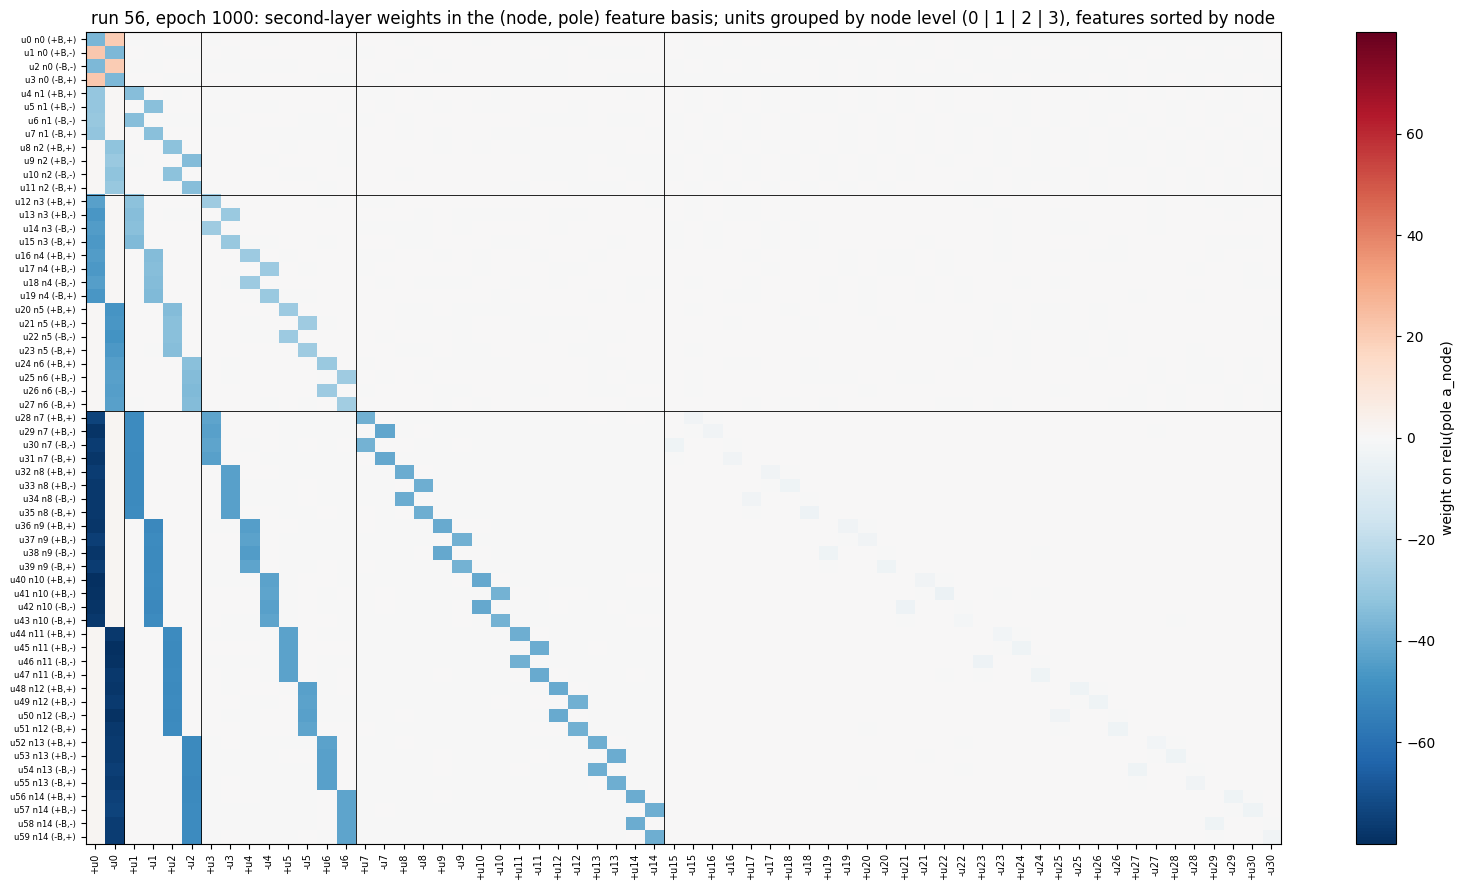

 unit  node  level   type  readout                                                    vetoes (weight < -1)  n positive weights  sum of positive weights largest positive  n small negatives (-1, 0)
    0     0      0 (+B,+)      7.7                                                          [(+u0, -36.5)]                  28                    23.31        -u0 20.45                         33
    1     0      0 (+B,-)     -7.8                                                          [(-u0, -35.9)]                  27                    23.86        +u0 21.55                         34
    2     0      0 (-B,-)     -7.7                                                          [(+u0, -35.9)]                  26                    23.29        -u0 20.46                         35
    3     0      0 (-B,+)      7.9                                                          [(-u0, -36.2)]                  28                    24.25        +u0 21.43                         33
    4     1      1 (

In [4]:
EPOCH_VIEW = EPOCH                                   # set to another stored epoch to view the weights there (the rest of the notebook keeps EPOCH); use_epoch(EPOCH) restores the globals
if EPOCH_VIEW != EPOCH: use_epoch(EPOCH_VIEW)
order_r = np.lexsort((-pole, top))
fig, ax = plt.subplots(figsize=(16, 9))
im = ax.imshow(Weff[:, order_r], cmap="RdBu_r", vmin=-np.abs(Weff).max(), vmax=np.abs(Weff).max(), aspect="auto"); plt.colorbar(im, ax=ax, label="weight on relu(pole a_node)")
ax.set_xticks(range(N_ROWS)); ax.set_xticklabels(rname[order_r], rotation=90, fontsize=7); ax.set_yticks(range(N_UNITS)); ax.set_yticklabels([f"u{u} n{unode[u]} {utype[u]}" for u in range(N_UNITS)], fontsize=6)
for k in (4, 12, 28): ax.axhline(k - 0.5, color="k", lw=0.6)
for k in np.cumsum([(NODE_LEVEL[top[order_r]] == l).sum() for l in range(4)]): ax.axvline(k - 0.5, color="k", lw=0.6)
ax.set_title(f"run {RUN}, epoch {EPOCH}: second-layer weights in the (node, pole) feature basis; units grouped by node level (0 | 1 | 2 | 3), features sorted by node"); plt.tight_layout(); plt.show()
# per unit: large negative weights (vetoes) and the sum of positive weights (background)
rec = []
for u in range(N_UNITS):
    w = Weff[u]; vet = [(rname[r], round(float(w[r]), 1)) for r in np.argsort(w) if w[r] < -1.0]; posw = w[w > 0]
    rec.append({"unit": u, "node": unode[u], "level": NODE_LEVEL[unode[u]], "type": utype[u], "readout": round(float(readout[u]), 1), "vetoes (weight < -1)": vet, "n positive weights": int((w > 0).sum()), "sum of positive weights": round(float(posw.sum()), 2), "largest positive": f"{rname[np.argmax(w)]} {w.max():.2f}", "n small negatives (-1, 0)": int(((w < 0) & (w > -1)).sum())})
recipes = pd.DataFrame(rec); print(recipes.to_string(index=False, max_colwidth=110))
if EPOCH_VIEW != EPOCH: use_epoch(EPOCH)


**Findings (run 56, last epoch).** Every unit has the same two-part structure: a few **vetoes**, large negative weights on the *wrong-side* feature of each node
on a path (the design's probe weights, -1 at init, grown 30-80x: 36 at level 0, 31-34 at level 1, 28-47 at level 2, 38-79 at level 3), and a
**background**, dozens of small positive weights summing to 2-3 (level 1-3 units) spread over the other features, plus 10-35 small negatives.
The cue blocks have turned into a 3-unit veto on one cue (level-3 units) or dissolved into the background. The **level-0 units are the
exception**: besides the 36 veto on the wrong side of u_0 they carry a weight of +20 on the *right-side* feature of u_0 (background sum 23),
so they output about 20 |a_0| on their half-space rather than a small constant; their readout is only 7.8. The readout grows with the unit's
level, 7.8 / 15 / 33 / 80, and has the path sign on every unit (no sign flips from init).


## 3. The level-3 units as leaf detectors: one per (level-4 node, label sign)

A level-3 unit of node `j` vetoes the wrong side of `u_0`, of `j`'s level-1 and level-2 ancestors and of `u_j` itself, which confines
it to the region of one child `m` of `j` (a level-4 node), and it vetoes one cue of `m`, which confines it further to one sign of `a_m`,
i.e. to one label. Its readout has the sign of that label.


In [5]:
lvl3 = [u for u in range(N_UNITS) if NODE_LEVEL[unode[u]] == 3]; rows3 = []; no_cue_veto = []
for u in lvl3:
    w = Weff[u]; vet_rows = [r for r in np.argsort(w) if w[r] < -1.0]; cue_vetoes = [r for r in vet_rows if top[r] >= 15 and cos[r] > 0.95]
    if not cue_vetoes: no_cue_veto.append(u); continue
    cue_r = cue_vetoes[0]; m, q = int(top[cue_r]), int(pole[cue_r]); label = -q
    region = m_reached == m; right = region & (np.sign(A[:, m]) == label); wrong = region & (np.sign(A[:, m]) == -label)
    b = F @ np.maximum(w, 0); own = [r for r in range(N_ROWS) if top[r] == m and pole[r] == label and cos[r] > 0.95]
    rows3.append({"unit": u, "node j": unode[u], "type": utype[u], "region m": m, "label served": label, "readout": round(float(readout[u]), 1), "vetoes on path (root..j)": [round(float(w[r]), 0) for r in vet_rows if top[r] < 15], "cue veto": f"{rname[cue_r]} {w[cue_r]:.1f}",
                  "own-sign cue weight": round(float(w[own[0]]), 2) if own else np.nan,
                  "active: region & right sign": round(float((h2[right, u] > 0).mean()), 3), "region & wrong sign": round(float((h2[wrong, u] > 0).mean()), 3), "off region": round(float((h2[~region, u] > 0).mean()), 4),
                  "output on region & right sign: mean": round(float(h2[right, u].mean()), 3), "= background b: corr": round(float(np.corrcoef(h2[right, u], b[right])[0, 1]), 3) if h2[right, u].std() > 0 else np.nan, "b mean / cv": f"{b.mean():.2f} / {b.std() / b.mean():.2f}"})
t3 = pd.DataFrame(rows3)
if len(t3): print(t3.to_string(index=False))
print(f"\n{len(t3)} of {len(lvl3)} level-3 units have a cue veto" + (f"; units without one: {no_cue_veto}" if no_cue_veto else ""))
leaf_complete = len(t3) == 32 and sorted(zip(t3["region m"], t3["label served"])) == sorted((m, s) for m in range(15, 31) for s in (1, -1))
print("each (level-4 node, label) served by exactly one level-3 unit:", leaf_complete, "| readout sign = label served:", bool((np.sign(t3.readout) == t3["label served"]).all()) if len(t3) else None)
if not leaf_complete and len(t3): print("  served cells (region, label) and how many units serve each:", dict(pd.Series(list(zip(t3["region m"], t3["label served"]))).value_counts().sort_index()))
print("veto size by level of the vetoed node (mean over level-3 units): " + ", ".join(f"level {l}: {np.mean([abs(Weff[u, r]) for u in lvl3 for r in range(N_ROWS) if Weff[u, r] < -1 and NODE_LEVEL[top[r]] == l] or [np.nan]):.0f}" for l in range(5)))


 unit  node j   type  region m  label served  readout     vetoes on path (root..j)  cue veto  own-sign cue weight  active: region & right sign  region & wrong sign  off region  output on region & right sign: mean  = background b: corr b mean / cv
   28       7 (+B,+)        15             1     78.0 [-74.0, -50.0, -42.0, -38.0] -u15 -2.9                 0.14                        0.998                0.319      0.0010                                0.170                 0.915 0.12 / 0.71
   29       7 (+B,-)        16            -1    -80.3 [-78.0, -50.0, -43.0, -41.0] +u16 -3.1                 0.25                        0.999                0.303      0.0011                                0.174                 0.908 0.12 / 0.71
   30       7 (-B,-)        15            -1    -78.6 [-76.0, -50.0, -42.0, -38.0] +u15 -3.5                 0.19                        1.000                0.266      0.0011                                0.175                 0.902 0.12 / 0.70
   31       

**Findings (run 56, last epoch).** The 32 level-3 units are exactly the 32 (level-4 node, label) detectors: every pair is served once, the readout sign is the
label served, the unit is active on essentially all points of its region with the right label sign (99.7-100%), on about 30% of the points
with the wrong sign (those with |a_m| small, where the 3-unit cue veto has not yet overcome the background; run 53: 9% with a 4-unit veto on
a 1.6-norm cue) and on 0.1% of the points outside its region. The vetoes grow toward the root (77 on the root's wrong side, 51 at level 1,
43 and 39 at levels 2-3, 3 on the cue; run 53: 54 / 36 / 30 / 30 / 4), about 1.4x run 53's. On its (region, sign) set the unit outputs its
background (correlation 0.92), a sum of small positive weights with mean 0.12 and coefficient of variation 0.7 across the sphere, output
0.17 on average (run 53: 0.05 / 0.55 / 0.07), and its readout of +-78 to +-81 turns that into a contribution of about +-13 to the logit.
The own-sign cue carries only a small positive weight (0.1-0.3), so the detector is an indicator of height b(x), not an |a_m| output.


## 4. The 28 lower-level units: coarse region detectors with weak label information


In [6]:
rows_lo = []
for u in [u for u in range(N_UNITS) if NODE_LEVEL[unode[u]] < 3]:
    w = Weff[u]; vet_rows = [r for r in np.argsort(w) if w[r] < -1.0]
    region = np.ones(len(A), bool)
    for r in vet_rows: region &= (pole[r] * A[:, top[r]] <= 0)                                    # the region the vetoes leave: right side of every vetoed node
    depth = max([NODE_LEVEL[top[r]] for r in vet_rows] or [-1]) + 1
    rows_lo.append({"unit": u, "node": unode[u], "level": NODE_LEVEL[unode[u]], "type": utype[u], "readout": round(float(readout[u]), 1), "vetoes": [rname[r] for r in vet_rows], "region: subtree of a node at level": depth, "region fraction": round(float(region.mean()), 3),
                    "active on region": round(float((h2[region, u] > 0).mean()), 3), "active off region": round(float((h2[~region, u] > 0).mean()), 4) if (~region).any() else np.nan, "mean output on region": round(float(h2[region, u].mean()), 3),
                    "corr(output, y) on region": round(float(np.corrcoef(h2[region, u], y[region])[0, 1]), 3) if h2[region, u].std() > 0 else np.nan, "cue weights: sum positive / sum negative": f"{w[(top >= 15)].clip(min=0).sum():.2f} / {(-w[(top >= 15)].clip(max=0)).sum():.2f}"})
tl = pd.DataFrame(rows_lo); print(tl.to_string(index=False, max_colwidth=60))
for lvl in range(4):
    us = np.where(NODE_LEVEL[unode] == lvl)[0]; cl = contrib[:, us].sum(1); print(f"level-{lvl} units together: mean |contribution to the logit| {np.abs(cl).mean():.2f}, corr with y {np.corrcoef(cl, y)[0, 1]:.3f}; |readout| mean {np.abs(readout[us]).mean():.1f}")


 unit  node  level   type  readout          vetoes  region: subtree of a node at level  region fraction  active on region  active off region  mean output on region  corr(output, y) on region cue weights: sum positive / sum negative
    0     0      0 (+B,+)      7.7           [+u0]                                   1            0.500             0.991             0.0046                  1.625                      0.015                              1.83 / 2.11
    1     0      0 (+B,-)     -7.8           [-u0]                                   1            0.500             0.988             0.0033                  1.707                     -0.015                              1.69 / 2.10
    2     0      0 (-B,-)     -7.7           [+u0]                                   1            0.500             0.989             0.0041                  1.618                     -0.012                              1.70 / 2.29
    3     0      0 (-B,+)      7.9           [-u0]                      

**Findings (run 56, last epoch).** A unit of a level-l node vetoes the wrong side of its own node and of its ancestors, so it is confined to the region of one
of its children: half-spaces at level 0, level-2 regions at level 1, level-3 regions at level 2, active on 88-99% of their region and on
under 0.6% outside it. They carry little label information (correlation of their output with the label 0.01 / 0.16 / 0.33 for levels
0 / 1 / 2; run 53: 0.05 / 0.22 / 0.53) and their contributions to the logit are small (0.7 / 0.8 / 2.1 against 11.6 for the leaf
detectors, with readouts 8 / 15 / 33 against 80). They are the coarse, early-captured units of the hierarchy that the leaf detectors made
redundant; what they still add is in section 5.


## 5. The readout: who decides, the decision near the boundary, and the sharp-veto limit


ablations (units of the removed levels silenced, the rest unchanged):
  all units                       : test error 0.0037, log loss 0.0175, logit rms 15.3
  level-3 units only              : test error 0.0184, log loss 0.0459, logit rms 13.2
  levels 2-3                      : test error 0.0097, log loss 0.0243, logit rms 14.7
  levels 1-3                      : test error 0.0071, log loss 0.0204, logit rms 15.0
  levels 0-2 (no leaf detectors)  : test error 0.2381, log loss 0.5477, logit rms 3.4

error rate by |a_m| (the coordinate of the level-4 split the point reaches): [('0-0.001', 0.1872), ('0.001-0.003', 0.0182), ('0.003-0.01', 0.007), ('0.01-0.03', 0.0034), ('0.03-0.1', 0.0018), ('0.1-1', 0.0006)]
logit: corr with sign(a_m) 0.883, with a_m 0.868; mean |logit| 13.5

leaf pairs near the split (16 regions with a (+, -) pair): slope 436, mean |crossing| 0.00034, spread of the crossing across points 0.00579


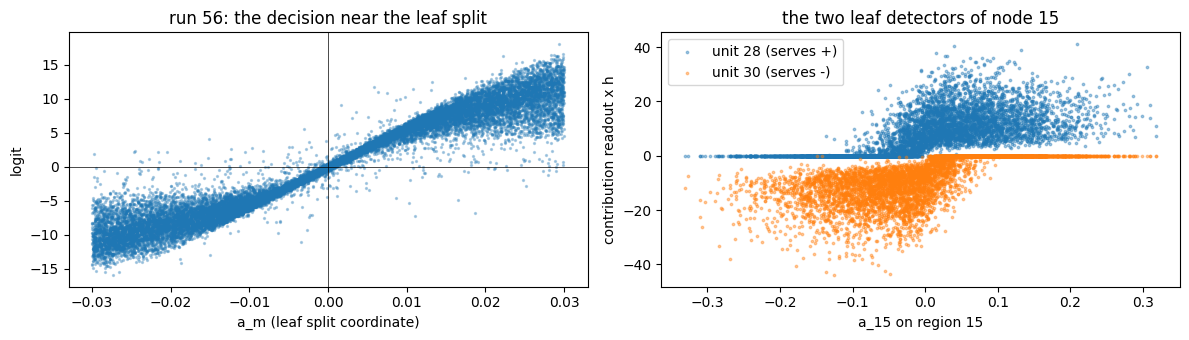

In [7]:
def logit_with(keep): return (h2 * keep[None, :]) @ readout
print("ablations (units of the removed levels silenced, the rest unchanged):")
for name, keep in [("all units", np.ones(N_UNITS)), ("level-3 units only", (NODE_LEVEL[unode] == 3).astype(float)), ("levels 2-3", (NODE_LEVEL[unode] >= 2).astype(float)), ("levels 1-3", (NODE_LEVEL[unode] >= 1).astype(float)), ("levels 0-2 (no leaf detectors)", (NODE_LEVEL[unode] < 3).astype(float))]:
    lg = logit_with(keep); print(f"  {name:32s}: test error {((lg >= 0) != (y > 0)).mean():.4f}, log loss {np.mean(np.logaddexp(0, -y * lg)):.4f}, logit rms {np.sqrt((lg ** 2).mean()):.1f}")
# the decision near the boundary
err = (logit >= 0) != (y > 0); bins = [0, 0.001, 0.003, 0.01, 0.03, 0.1, 1]
print("\nerror rate by |a_m| (the coordinate of the level-4 split the point reaches):", [(f"{bins[i]}-{bins[i + 1]}", round(float(err[(np.abs(am) >= bins[i]) & (np.abs(am) < bins[i + 1])].mean()), 4)) for i in range(len(bins) - 1)])
print(f"logit: corr with sign(a_m) {np.corrcoef(logit, np.sign(am))[0, 1]:.3f}, with a_m {np.corrcoef(logit, am)[0, 1]:.3f}; mean |logit| {np.abs(logit).mean():.1f}")
# per region: the pair's logit near the split is (b+ - b-)(x) + slope x a_m; the zero crossing and its spread across points (needs a (+, -) pair of leaf detectors for the region)
cross = []; served = {(int(r["region m"]), int(r["label served"])): int(r.unit) for _, r in t3.iterrows()} if len(t3) else {}
for m in range(15, 31):
    if (m, 1) not in served or (m, -1) not in served: continue
    up, um = served[(m, 1)], served[(m, -1)]; sel = (m_reached == m) & (np.abs(am) < 0.02)
    d = contrib[sel, up] + contrib[sel, um]; X = np.c_[np.ones(sel.sum()), am[sel]]; co = np.linalg.lstsq(X, d, rcond=None)[0]
    if co[1] == 0: continue
    bp = h1[sel] @ np.maximum(W2[up], 0) * readout[up]; bm = h1[sel] @ np.maximum(W2[um], 0) * readout[um]; cross.append({"m": m, "slope of pair logit in a_m": co[1], "zero crossing a_m*": -co[0] / co[1], "sd of crossing across x": np.std(bp + bm) / co[1]})
cross = pd.DataFrame(cross)
if len(cross): print(f"\nleaf pairs near the split ({len(cross)} regions with a (+, -) pair): slope {cross['slope of pair logit in a_m'].mean():.0f}, mean |crossing| {cross['zero crossing a_m*'].abs().mean():.5f}, spread of the crossing across points {cross['sd of crossing across x'].mean():.5f}")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5)); sel = np.abs(am) < 0.03
ax[0].scatter(am[sel][:20000], logit[sel][:20000], s=2, alpha=0.3); ax[0].axhline(0, color="k", lw=0.5); ax[0].axvline(0, color="k", lw=0.5); ax[0].set_xlabel("a_m (leaf split coordinate)"); ax[0].set_ylabel("logit"); ax[0].set_title(f"run {RUN}: the decision near the leaf split")
m_show = next((m for m in range(15, 31) if (m, 1) in served and (m, -1) in served), None)
if m_show is not None:
    u_plus, u_minus = served[(m_show, 1)], served[(m_show, -1)]; rr = m_reached == m_show
    ax[1].scatter(A[rr, m_show], contrib[rr, u_plus], s=3, alpha=0.4, label=f"unit {u_plus} (serves +)"); ax[1].scatter(A[rr, m_show], contrib[rr, u_minus], s=3, alpha=0.4, label=f"unit {u_minus} (serves -)")
    ax[1].set_xlabel(f"a_{m_show} on region {m_show}"); ax[1].set_ylabel("contribution readout x h"); ax[1].legend(); ax[1].set_title(f"the two leaf detectors of node {m_show}")
plt.tight_layout(); plt.show()


In [8]:
# The sharp-veto limit: rows snapped onto their closest +-u_j (tilt removed) and the vetoes (Weff < -1) scaled by K, everything else unchanged. With the trained (tilted) rows the same scaling cuts into the cells.
W1x = nrm[:, None] * pole[:, None] * U[top]; h1x = np.maximum(x @ W1x.T, 0)
units3 = [int(u) for u in t3.unit] if len(t3) else []; s3 = np.array([int(t3.set_index("unit").loc[u, "label served"]) for u in units3]); cell = {u: (int(t3.set_index("unit").loc[u, "region m"]), int(t3.set_index("unit").loc[u, "label served"])) for u in units3}
def leaf_activity(h2k): return np.mean([(h2k[(m_reached == cell[u][0]) & (np.sign(am) == cell[u][1]), u] > 0).mean() for u in units3]) if units3 else np.nan
print(f"rows -> exact normals, vetoes x K (full network / the {len(units3)} leaf detectors with a +-1 readout):")
for K in (1, 3, 10, 100, 1000):
    W2k = np.where(Weff < -1, K * W2, W2); h2k = np.maximum(h1x @ W2k.T, 0); lg = h2k @ readout; lg32 = h2k[:, units3] @ s3 if units3 else np.zeros(len(y))
    print(f"  K = {K:5d}: full error {((lg >= 0) != (y > 0)).mean():.5f}, log loss {np.mean(np.logaddexp(0, -y * lg)):.4f} | leaf units: error {((lg32 >= 0) != (y > 0)).mean():.5f}, best log loss over readout scales {min(np.mean(np.logaddexp(0, -y * c * lg32)) for c in (30, 100, 300, 1000, 3000)):.4f} | leaf units active on own (region, sign) {leaf_activity(h2k):.3f}")
for K in (1, 10):
    W2k = np.where(Weff < -1, K * W2, W2); h2k = np.maximum(h1 @ W2k.T, 0); lg = h2k @ readout
    print(f"  trained rows, vetoes x {K:2d}: full error {((lg >= 0) != (y > 0)).mean():.5f}, leaf units active on own (region, sign) {leaf_activity(h2k):.3f}")


rows -> exact normals, vetoes x K (full network / the 32 leaf detectors with a +-1 readout):
  K =     1: full error 0.01684, log loss 0.0935 | leaf units: error 0.04215, best log loss over readout scales 0.1289 | leaf units active on own (region, sign) 1.000
  K =     3: full error 0.00428, log loss 0.0205 | leaf units: error 0.01368, best log loss over readout scales 0.0443 | leaf units active on own (region, sign) 1.000
  K =    10: full error 0.00112, log loss 0.0051 | leaf units: error 0.00411, best log loss over readout scales 0.0120 | leaf units active on own (region, sign) 1.000
  K =   100: full error 0.00009, log loss 0.0009 | leaf units: error 0.00042, best log loss over readout scales 0.0016 | leaf units active on own (region, sign) 1.000
  K =  1000: full error 0.00000, log loss 0.0004 | leaf units: error 0.00003, best log loss over readout scales 0.0002 | leaf units active on own (region, sign) 1.000


  trained rows, vetoes x  1: full error 0.00366, leaf units active on own (region, sign) 0.999
  trained rows, vetoes x 10: full error 0.04425, leaf units active on own (region, sign) 0.892


**Findings (run 56, last epoch).**
- **The leaf detectors decide, the lower levels add margin.** Silencing everything but the 32 level-3 units leaves a working classifier
  (test error 1.8%, logit rms 13); silencing the leaf detectors instead leaves 24% error. Adding levels 2, 1 and 0 brings the error to
  0.97%, 0.71% and 0.37%; the lower levels contribute an offset that follows the leaf detectors' sign (level-2 total correlates 0.57 with
  the label). In run 53 the same ablation ladder read 1.1% -> 0.22% -> 0.20% -> 0.14% through the gated third layer; here the readout is
  linear, so the sign of the logit is exactly the sign of the units' weighted sum.
- **The decision near the leaf split is linear in a_m.** On region m the two detectors output their backgrounds and the one serving the
  wrong sign is cut by its cue veto, so the pair's logit is `(b_+ - b_-)(x) + 436 a_m` near a_m = 0: a line crossing zero at |a_m| of
  0.0003 on average, with a spread of 0.006 across points (the backgrounds' fluctuation divided by the slope; run 53: slope 300, spread
  0.0013). Errors live where |a_m| is small: 19% for |a_m| < 0.001, 1.8% for 0.001-0.003, 0.7% for 0.003-0.01, under 0.2% beyond
  0.03, which is the 0.37% test error (run 53: 0.13%, with the sharper crossing).
- **The sharp-veto limit.** Snap the rows onto exact +-u_j and scale only the vetoes by K, leaving backgrounds and readout alone: the
  full network's error goes 1.7% (K = 1: the tilt was load-bearing) -> 0.43% -> 0.11% -> 0.009% -> 0 for K = 3 / 10 / 100 / 1000, the
  32 leaf detectors with a +-1 readout likewise to 3 in 100k, and the log loss to 0.0004 / 0.0002. The crossing offset is
  (b_+ - b_-)/(veto slope), so it vanishes as 1/K, and the leaf units stay active on 100% of their cells. With the trained, tilted rows
  the same vetoes x10 cut into the cells (units active on 89% of their set, error 4.4%): the manufactured biases and the moderate vetoes
  are a matched pair, and exact normals with sharp vetoes are the clean limit of the same design.
- **The network therefore implements the tree as** `sum over the 32 (leaf, sign) cells of readout_(m,s) b(x) 1[x reaches m, sign(a_m) = s]`,
  with cell membership computed by vetoes on the wrong side of every split on the path, the sign by a veto on the wrong cue, the readout
  carrying the label sign, and the coarse units adding a sign-following margin. Compared with run 53 the same anatomy appears with the
  weights redistributed: larger probes and vetoes, smaller cues, a direct readout of 80 on the leaf detectors in place of the factorised
  one, and a boundary four times less sharp.
